### Импорт

In [33]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns

### Константы

In [3]:
ROOT_DIR = Path.cwd()
DATA_DIR = ROOT_DIR / 'data'
WEATHER = DATA_DIR / 'weather1.csv'

### Решение

Для  визуализации  можно  использовать  любые  библиотеки  на  свой  выбор, но обязательно продемонстрировать хотя бы 2 разных (например, matplotlib и seaborn).

1.  Загрузите данные из файла «weather1.csv» о погоде в Перми.

Загрузите только следующие столбцы:
- Местное время в Перми 
- T (температура воздуха в градусах Цельсия) 
- P (атмосферное давление в мм.рт.ст.) 
- U (относительная влажность в %) 
- Ff (скорость ветра в м/с) 
- N (облачность) 
- H (высота основания облаков, м) 
- VV (горизонтальная дальность видимости в км)

In [4]:
fields = ['Местное время в Перми', 'T', 'P', 'U', 'Ff', 'N', 'H', 'VV']
df = pd.read_csv(WEATHER, sep=';', usecols=fields)

In [5]:
df.head()

,Местное время в Перми,T,P,U,Ff,N,H,VV
0,31.12.2021 23:00,-9.8,762.5,83,3,100%.,600-1000,4.0
1,31.12.2021 20:00,-10.6,764.2,81,3,100%.,1000-1500,4.0
2,31.12.2021 17:00,-11.6,765.5,79,2,"90 или более, но не 100%",1000-1500,10.0
3,31.12.2021 14:00,-11.9,766.7,77,1,100%.,1000-1500,20.0
4,31.12.2021 11:00,-13.6,767.5,79,1,100%.,1000-1500,10.0


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2919 entries, 0 to 2918
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Местное время в Перми  2919 non-null   str    
 1   T                      2919 non-null   float64
 2   P                      2917 non-null   float64
 3   U                      2919 non-null   int64  
 4   Ff                     2919 non-null   int64  
 5   N                      2916 non-null   str    
 6   H                      2551 non-null   str    
 7   VV                     2917 non-null   float64
dtypes: float64(3), int64(2), str(3)
memory usage: 182.6 KB


2.  (1 балл) Постройте точечную диаграмму (диаграмму рассеяния) по признакам температуры и относительной влажности.

In [7]:
fig_1 = go.Figure()
fig_1.add_trace(go.Scatter(x=df['T'], y=df['U'], mode='markers'))
fig_1.update_layout(
    title='Диаграмма рассеяния по температуре (T) и относительной влажности (U)',
    xaxis_title='Температура (T)',
    yaxis_title='Относительная влажность (U)'
    )
fig_1.show()

3.  (1 балл) На  построенной  в  предыдущем  пункте  диаграмме  выделите  точки разными цветами в зависимости от облачности: синим – для которых облачность составляет 100%; красным – все остальные. 

In [8]:
df['N'].unique()

<StringArray>
[                                                             '100%.',
                                          '90  или более, но не 100%',
                                                          '70 – 80%.',
                                                            '20–30%.',
                                                               '50%.',
                                                       'Облаков нет.',
                                                               '40%.',
                                                               '60%.',
                                            '10%  или менее, но не 0',
 'Небо не видно из-за тумана и/или других метеорологических явлений.',
                                                                  nan]
Length: 11, dtype: str

In [9]:
colors = df['N'].apply(lambda n: 'red' if n == '100%.' else 'blue')

fig_1.update_traces(marker={'color': colors})
fig_1.show()

4.  (1 балл)  Постройте  линейную диаграмму (график) изменения температуры  в зависимости от местного времени. 

In [10]:
df['Местное время в Перми'] = pd.to_datetime(df['Местное время в Перми'], format='%d.%m.%Y %H:%M')

In [11]:
df.head(1)

,Местное время в Перми,T,P,U,Ff,N,H,VV
0,2021-12-31 23:00:00,-9.8,762.5,83,3,100%.,600-1000,4.0


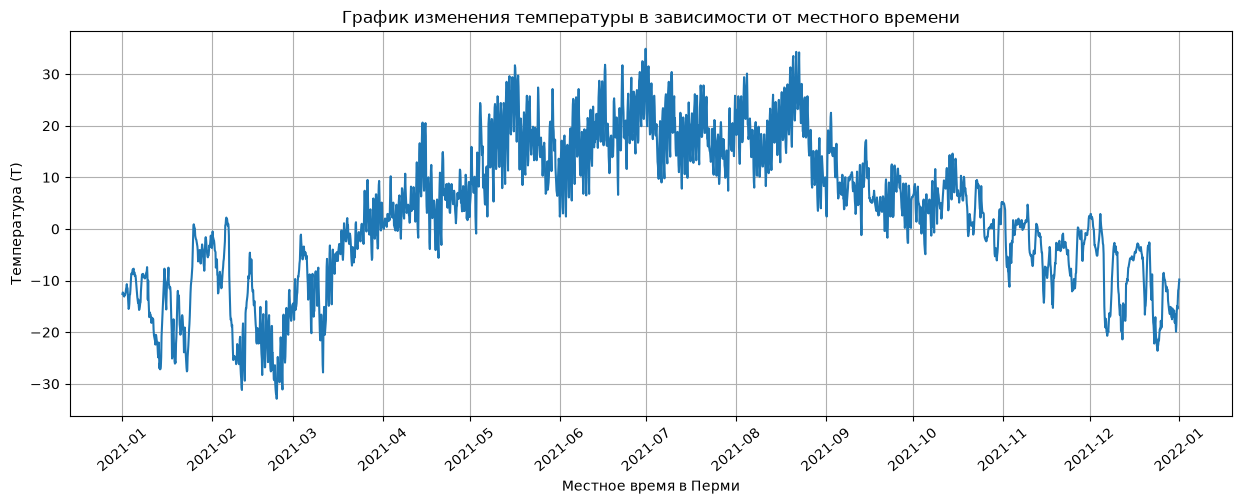

In [12]:
fig_2, ax_2 = plt.subplots(figsize=(15, 5))
ax_2.plot(df['Местное время в Перми'], df['T'])
ax_2.set(xlabel='Местное время в Перми', ylabel='Температура (T)',
       title='График изменения температуры в зависимости от местного времени')
ax_2.grid()
ax_2.tick_params(axis='x', rotation=40)
ax_2.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
plt.show()

5.  (2 балла) Посчитайте по имеющимся данным среднемесячную температуру и постройте  столбчатую  диаграмму  (вертикальную)  зависимости  средней температуры от месяца. 

Подсказка: создайте отдельный столбец с номером месяца (вычислив его из столбца «Местное время»), а затем сгруппируйте данные по этому столбцу. 

In [13]:
df['Месяц'] = df['Местное время в Перми'].dt.month

In [14]:
df.head(1)

,Местное время в Перми,T,P,U,Ff,N,H,VV,Месяц
0,2021-12-31 23:00:00,-9.8,762.5,83,3,100%.,600-1000,4.0,12


In [15]:
group_month_mean_t = df.groupby('Месяц').agg(mean_t=('T', 'mean'))
group_month_mean_t

,mean_t
Месяц,
1,-12.958871
2,-17.419643
3,-5.660484
4,5.382500
5,16.275806
6,18.898333
7,18.444355
8,18.568145
9,7.556067


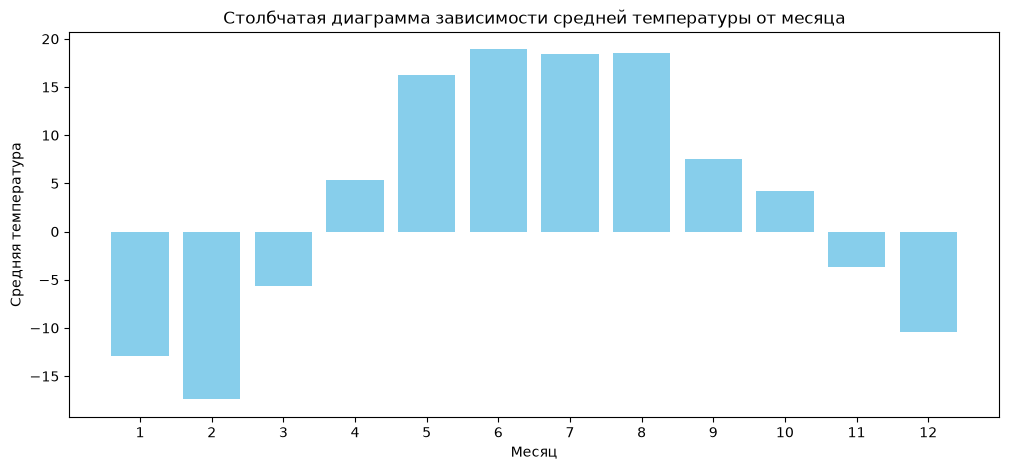

In [16]:
plt.figure(figsize=(12, 5))
plt.bar(group_month_mean_t.index, group_month_mean_t['mean_t'], color="skyblue")
plt.xlabel("Месяц")
plt.ylabel("Средняя температура")
plt.title("Столбчатая диаграмма зависимости средней температуры от месяца")
plt.xticks(ticks=group_month_mean_t.index)
plt.show()

6.  (1  балл)  Постройте  ленточную  диаграмму  (горизонтальную),  отразив  на  ней количество имеющихся наблюдений для каждого варианта облачности. 

In [17]:
group_count_n = df.groupby('N').agg(count_n=('N', 'count'))
group_count_n

,count_n
N,
"10% или менее, но не 0",66
100%.,1427
20–30%.,251
40%.,111
50%.,83
60%.,106
70 – 80%.,285
"90 или более, но не 100%",222
Небо не видно из-за тумана и/или других метеорологических явлений.,1


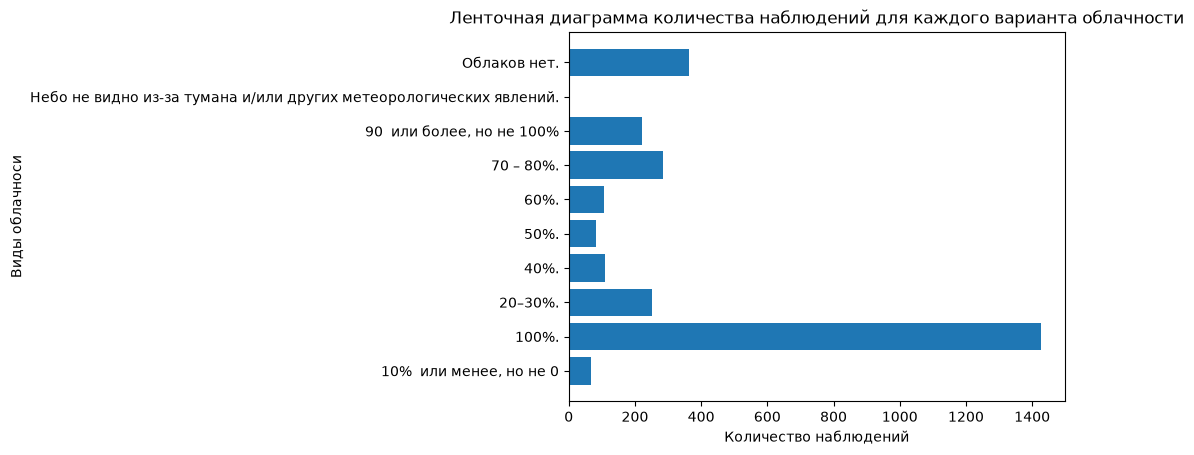

In [21]:
fig_3, ax_3 = plt.subplots()
ax_3.barh(group_count_n.index, group_count_n['count_n'])
ax_3.set(xlabel='Количество наблюдений', ylabel='Виды облачноси', title='Ленточная диаграмма количества наблюдений для каждого варианта облачности')
plt.show()

7.  (1 балл) Постройте гистограмму частот для температуры. На гистограмме должно быть 10 диапазонов температуры. 

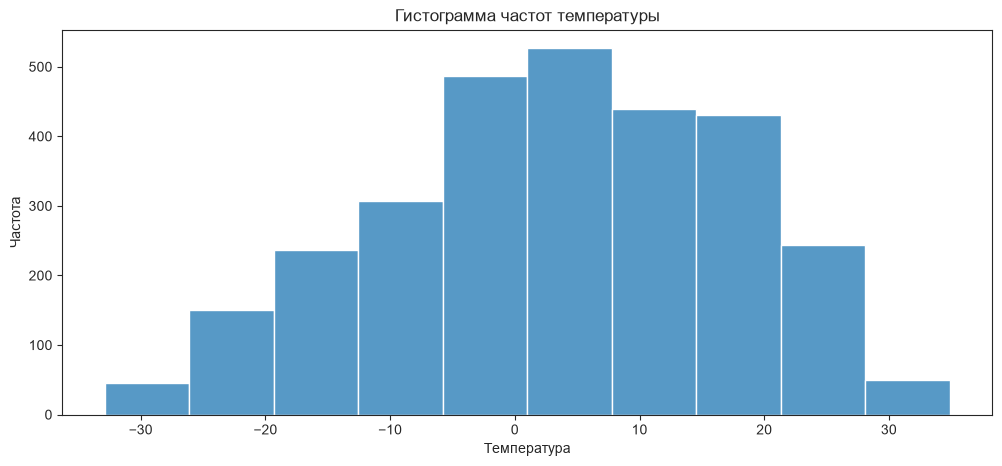

In [31]:
sns.set_style('ticks')
plt.figure(figsize=(12, 5))
sns.histplot(df['T'], bins=10)
plt.xlabel("Температура")
plt.ylabel("Частота")
plt.title("Гистограмма частот температуры")
plt.show()

8.  (2 балла) Разбейте данные на 3 группы по значению горизонтальной дальности видимости (одна группа –  дальность видимости менее 5 км, вторая –  от 5 до 15 км(включительно), третья – более 15 км). В одной области для каждой группы постройте  boxplot (диаграмму  «ящик  с  усами») для  признака  «атмосферное давление».

In [32]:
df['VV'].unique()

array([ 4.  , 10.  , 20.  ,  2.  ,  1.  ,  0.5 ,  0.05,   nan,  0.2 ])

In [34]:
def get_cat_vv(x):
    if x < 5:
        return 'Видимость менее 5 км'
    if 5 <= x <= 15:
        return 'Видимость от 5 до 15 км'
    if x > 15:
        return 'Видимость более 15 км'

In [39]:
df['Категория VV'] = df['VV'].apply(get_cat_vv)

In [58]:
df.sample(5)

,Местное время в Перми,T,P,U,Ff,N,H,VV,Месяц,Категория VV
1968,2021-04-29 20:00:00,6.8,759.3,65,4,60%.,600-1000,20.0,4,Видимость более 15 км
2884,2021-01-05 08:00:00,-9.1,781.1,84,1,100%.,600-1000,10.0,1,Видимость от 5 до 15 км
2279,2021-03-21 23:00:00,-6.5,753.4,65,2,60%.,600-1000,20.0,3,Видимость более 15 км
2542,2021-02-17 02:00:00,-22.2,766.9,75,1,100%.,2000-2500,4.0,2,Видимость менее 5 км
414,2021-11-10 05:00:00,-3.9,757.3,75,4,100%.,300-600,4.0,11,Видимость менее 5 км


In [40]:
df[df['VV'].isna()].head()

,Местное время в Перми,T,P,U,Ff,N,H,VV,Месяц,Категория VV
1373,2021-07-13 05:00:00,7.8,760.9,87,1,NaN,NaN,NaN,7,NaN
1670,2021-06-06 02:00:00,11.4,764.8,70,1,NaN,NaN,NaN,6,NaN


In [62]:
fig_4 = px.box(df, x='Категория VV', y='P')
fig_4.update_layout(
    title='Ящик с усами для признака "Атмосферное давление" по категориям "Дальности видимости"',
    xaxis_title='Категория дальности видимости',
    yaxis_title='Атмосферное давление'
    )
fig_4.show()

9.  (1  балл) Постройте круговую  диаграмму  для  признака  «высота  основания облаков». 

In [63]:
df['H'].unique()

<StringArray>
[                        '600-1000',                        '1000-1500',
                        '2000-2500', '2500 или более, или облаков нет.',
                          '300-600',                                nan,
                          '200-300',                          '100-200']
Length: 8, dtype: str

In [77]:
fig_5 = go.Figure(data=[go.Pie(labels=df['H'], textinfo='value+percent')])
fig_5.update_layout(
    title='Круговая диаграмма для признака "Высота основания облаков',
    legend_title_text='Категория высоты основания облаков:',
    width=950,
    height=550
)
fig_5.show()